In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("loan_approval_dataset.csv")

In [ ]:
print(df.head())
print(df.info())
print(df.shape)
print(df.columns)

   no_of_dependents  education  self_employed  income_annum  loan_amount  \
0                 2          0              0       9600000     29900000   
1                 0          1              1       4100000     12200000   
2                 3          0              0       9100000     29700000   
3                 3          0              0       8200000     30700000   
4                 5          1              1       9800000     24200000   

   loan_term  cibil_score  residential_assets_value  commercial_assets_value  \
0         12          778                   2400000                 17600000   
1          8          417                   2700000                  2200000   
2         20          506                   7100000                  4500000   
3          8          467                  18200000                  3300000   
4         20          382                  12400000                  8200000   

   luxury_assets_value  bank_asset_value  loan_status  loan_to

In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
df['loan_to_income_ratio'] = df['loan_amount']/ df['income_annum']
print(df['loan_to_income_ratio'].head(2))

0    3.114583
1    2.975610
Name: loan_to_income_ratio, dtype: float64


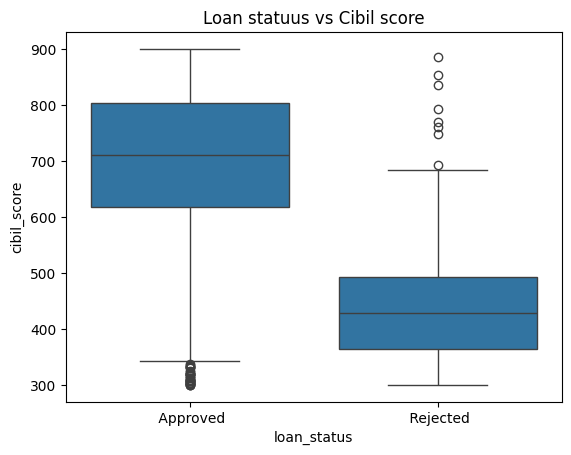

In [ ]:
sns.boxplot(x ="loan_status",y = "cibil_score",data = df)
plt.title("Loan statuus vs Cibil score")
plt.show()

In [ ]:
df.groupby('loan_status')['cibil_score'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Approved,2656.0,703.461973,125.249016,300.0,618.0,711.0,803.0,900.0
Rejected,1613.0,429.468072,78.401752,300.0,364.0,429.0,493.0,885.0


In [ ]:
print("\n High cibil score yet rejected")
print(df[(df['cibil_score']>700) & (df['loan_status'] == "Rejected")].shape[0])


 High cibil score yet rejected
0


In [ ]:
print("\n Approved with low cibil score ")
print(df[(df['cibil_score']<500) & (df['loan_status']=='Approved')].shape[0])


 Approved with low cibil score 
0


In [ ]:
df = df.drop('loan_id',axis = 1)

In [ ]:
df.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status', 'loan_to_income_ratio'],
      dtype='object')

In [ ]:
df.head(2)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,loan_to_income_ratio
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,NaN,3.114583
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,NaN,2.975610


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['education'] = le.fit_transform(df['education'])
df['self_employed'] = le.fit_transform(df['self_employed'])
df['loan_status'] = le.fit_transform(df['loan_status'])

In [ ]:
df['loan_status'] = 1 - df["loan_status"]
print(df['loan_status'].value_counts())

loan_status
1    2656
0    1613
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop("loan_status",axis =1)
y = df['loan_status']

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3415, 12)
(854, 12)
(3415,)
(854,)


In [ ]:
print("X columns:",X.columns)

X columns: Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_to_income_ratio'],
      dtype='object')


In [ ]:
X.isnull().sum()

,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0
luxury_assets_value,0


In [ ]:
y_train.isnull().sum()

np.int64(0)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [ ]:
print(df['loan_status'].value_counts())

loan_status
1    2656
0    1613
Name: count, dtype: int64


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print("Accuracy score :", accuracy_score(y_test,y_pred))
print("Classification report :\n",classification_report(y_test,y_pred,target_names = ["Rejected",
                                                                                      "Approved"]))

Accuracy score : 0.8032786885245902
Classification report :
               precision    recall  f1-score   support

    Rejected       0.80      0.62      0.70       318
    Approved       0.80      0.91      0.85       536

    accuracy                           0.80       854
   macro avg       0.80      0.77      0.78       854
weighted avg       0.80      0.80      0.80       854



In [ ]:
print("Confusion matrix:",confusion_matrix(y_test,y_pred))

Confusion matrix: [[198 120]
 [ 48 488]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
y_pred = dt.predict(X_test)

In [ ]:
print("Decision tree accuracy:",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred,target_names=['Rejected','Approved']))

Decision tree accuracy: 0.9964871194379391
[[317   1]
 [  2 534]]
              precision    recall  f1-score   support

    Rejected       0.99      1.00      1.00       318
    Approved       1.00      1.00      1.00       536

    accuracy                           1.00       854
   macro avg       1.00      1.00      1.00       854
weighted avg       1.00      1.00      1.00       854



In [ ]:
train_acc = accuracy_score(y_train,dt.predict(X_train))
test_acc = accuracy_score(y_test,dt.predict(X_test))
print("Train accuracy:",train_acc)
print("Test accuracy:",test_acc)

Train accuracy: 1.0
Test accuracy: 0.9964871194379391


In [ ]:
print("tree depth:",dt.get_depth())
print("Leaves:",dt.get_n_leaves())


tree depth: 8
Leaves: 23


In [ ]:
from sklearn.tree import plot_tree

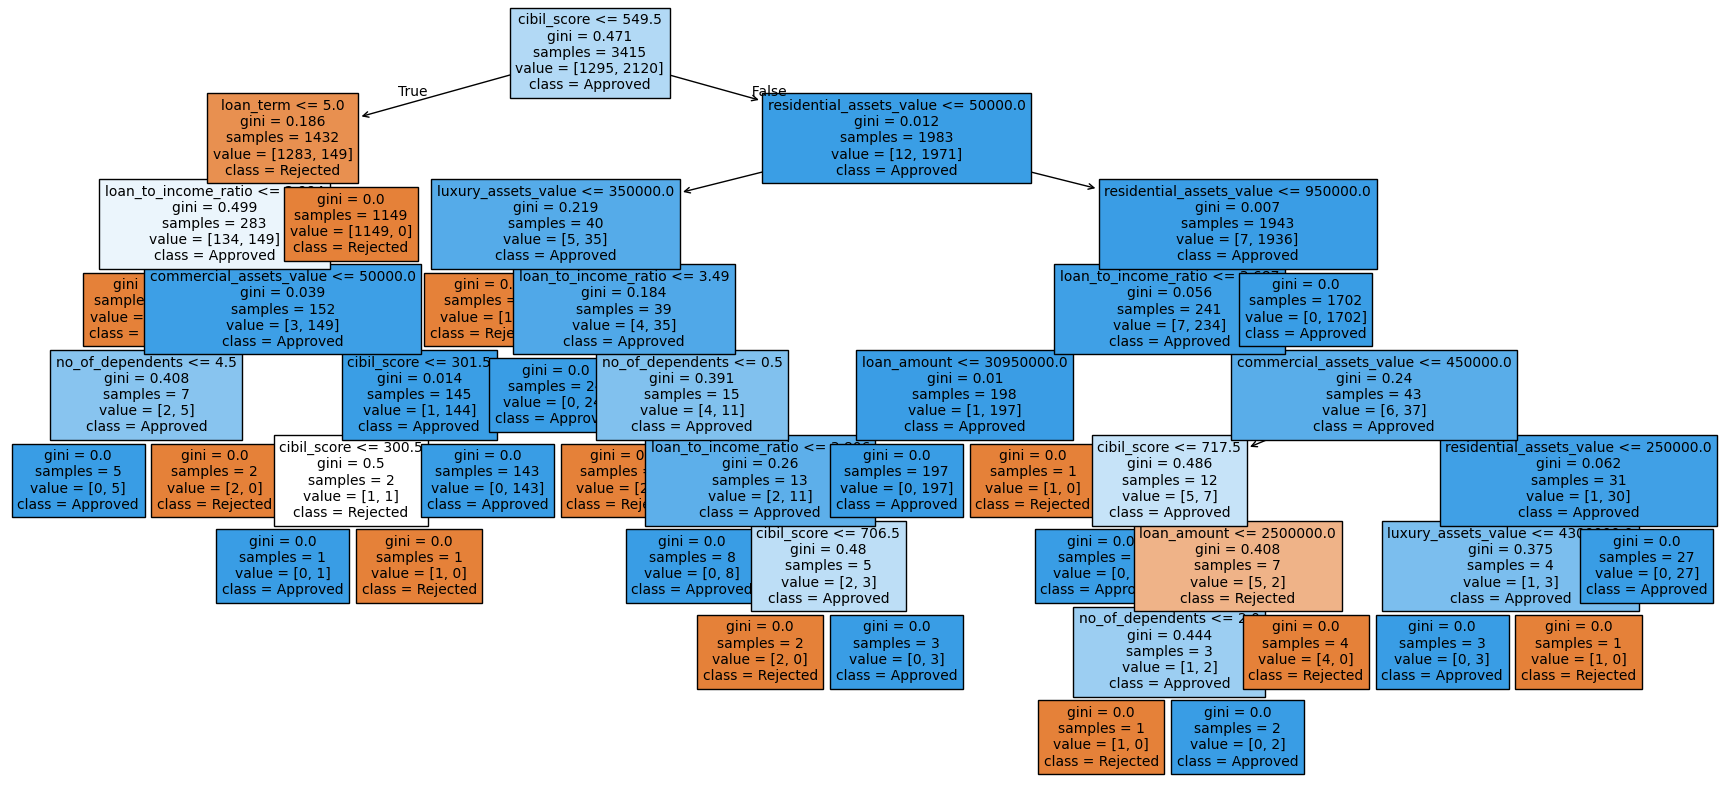

In [ ]:
plt.figure(figsize=(22,10))
plot_tree(dt,filled=True,feature_names=X.columns.tolist(),
          class_names=['Rejected','Approved'],
          fontsize = 10)
plt.show()

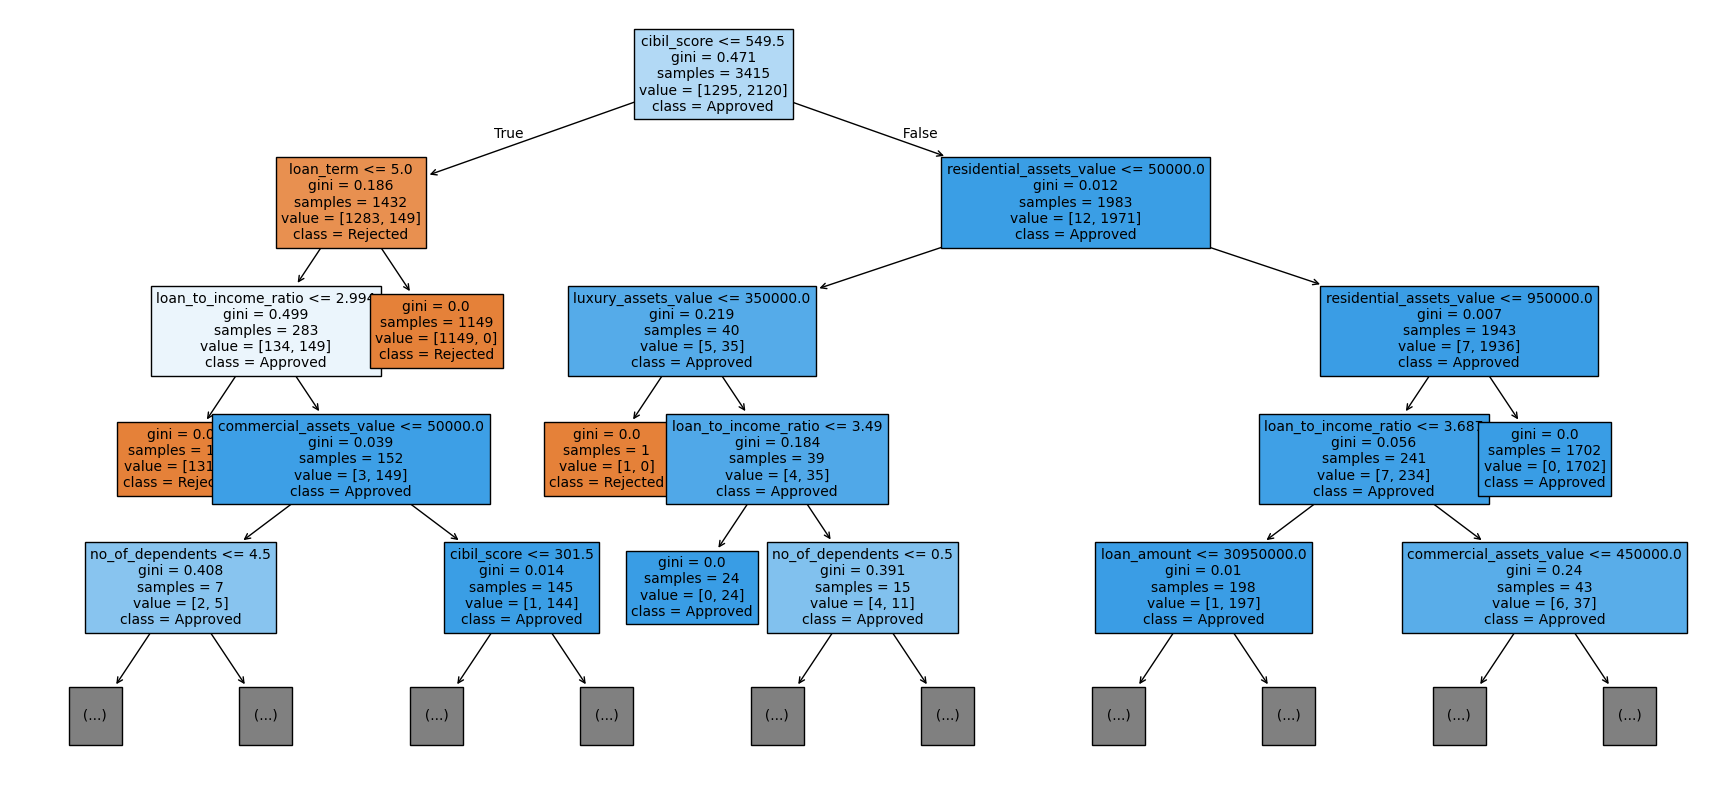

In [ ]:
plt.figure(figsize=(22,10))
plot_tree(dt,filled=True,feature_names=X.columns.tolist(),
          class_names=['Rejected','Approved'],
          fontsize = 10,max_depth =4)
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(n_estimators=200,random_state=42,max_depth = 10)
rf.fit(X_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=200, random_state=42)

In [ ]:
y_pred_rf = rf.predict(X_test)

In [ ]:
print("Decision tree accuracy:",accuracy_score(y_test,y_pred_rf))
print(confusion_matrix(y_test,y_pred_rf))
print(classification_report(y_test,y_pred_rf,target_names=['Rejected','Approved']))

Decision tree accuracy: 0.9988290398126464
[[317   1]
 [  0 536]]
              precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00       318
    Approved       1.00      1.00      1.00       536

    accuracy                           1.00       854
   macro avg       1.00      1.00      1.00       854
weighted avg       1.00      1.00      1.00       854



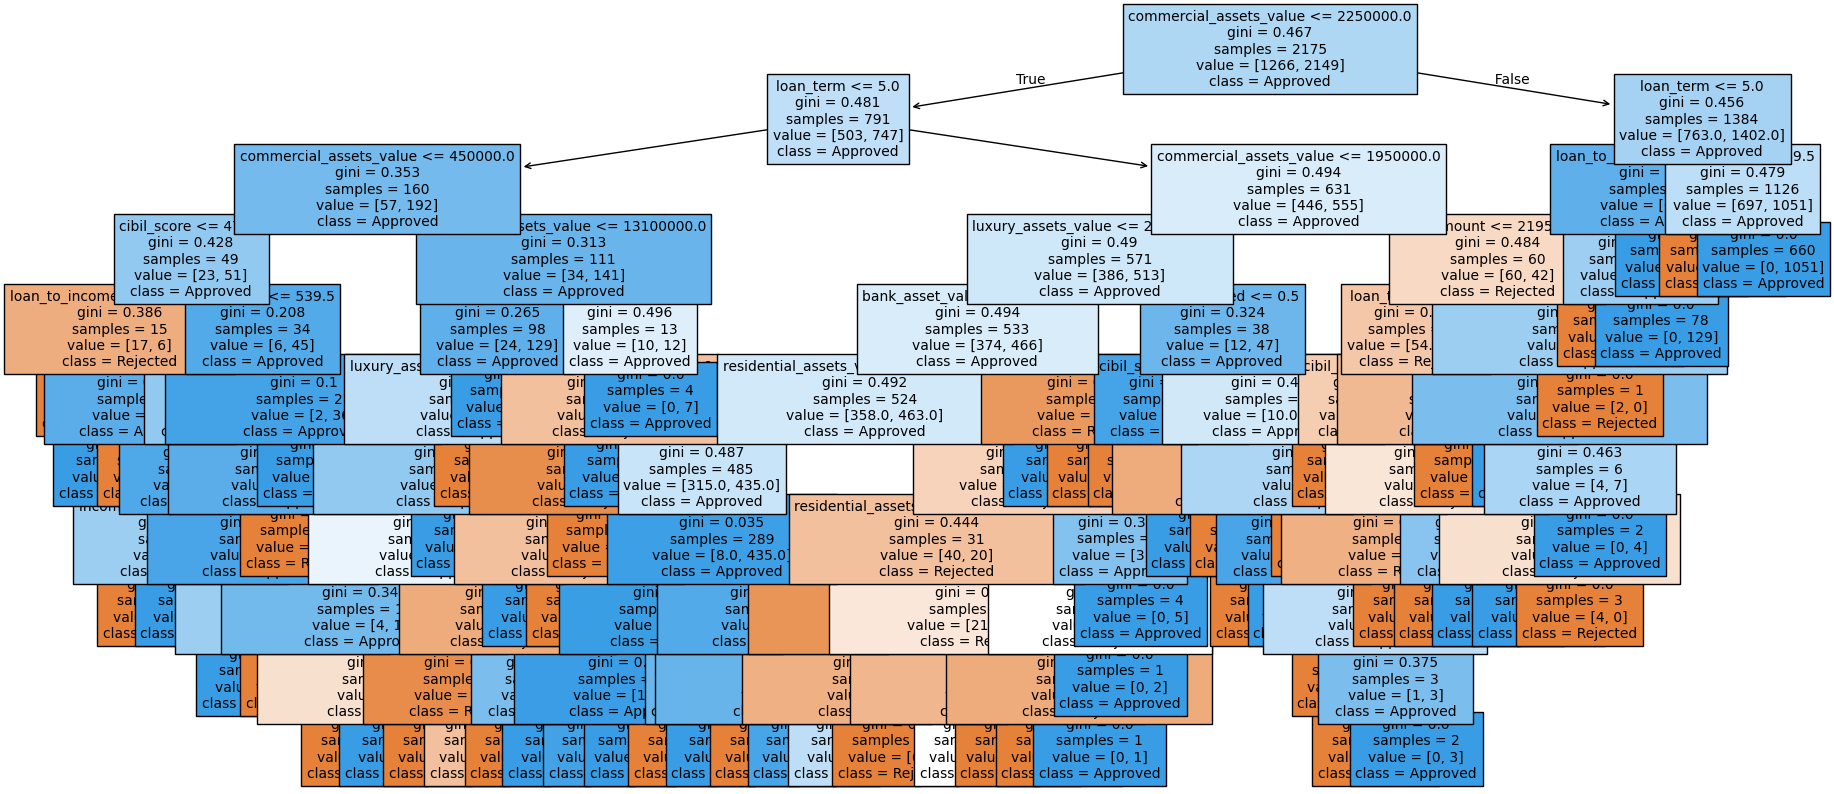

In [ ]:
single_tree = rf.estimators_[0]
plt.figure(figsize=(22,10))
plot_tree(single_tree,filled=True,feature_names=X.columns.tolist(),
          class_names=['Rejected','Approved'],
          fontsize = 10)
plt.show()

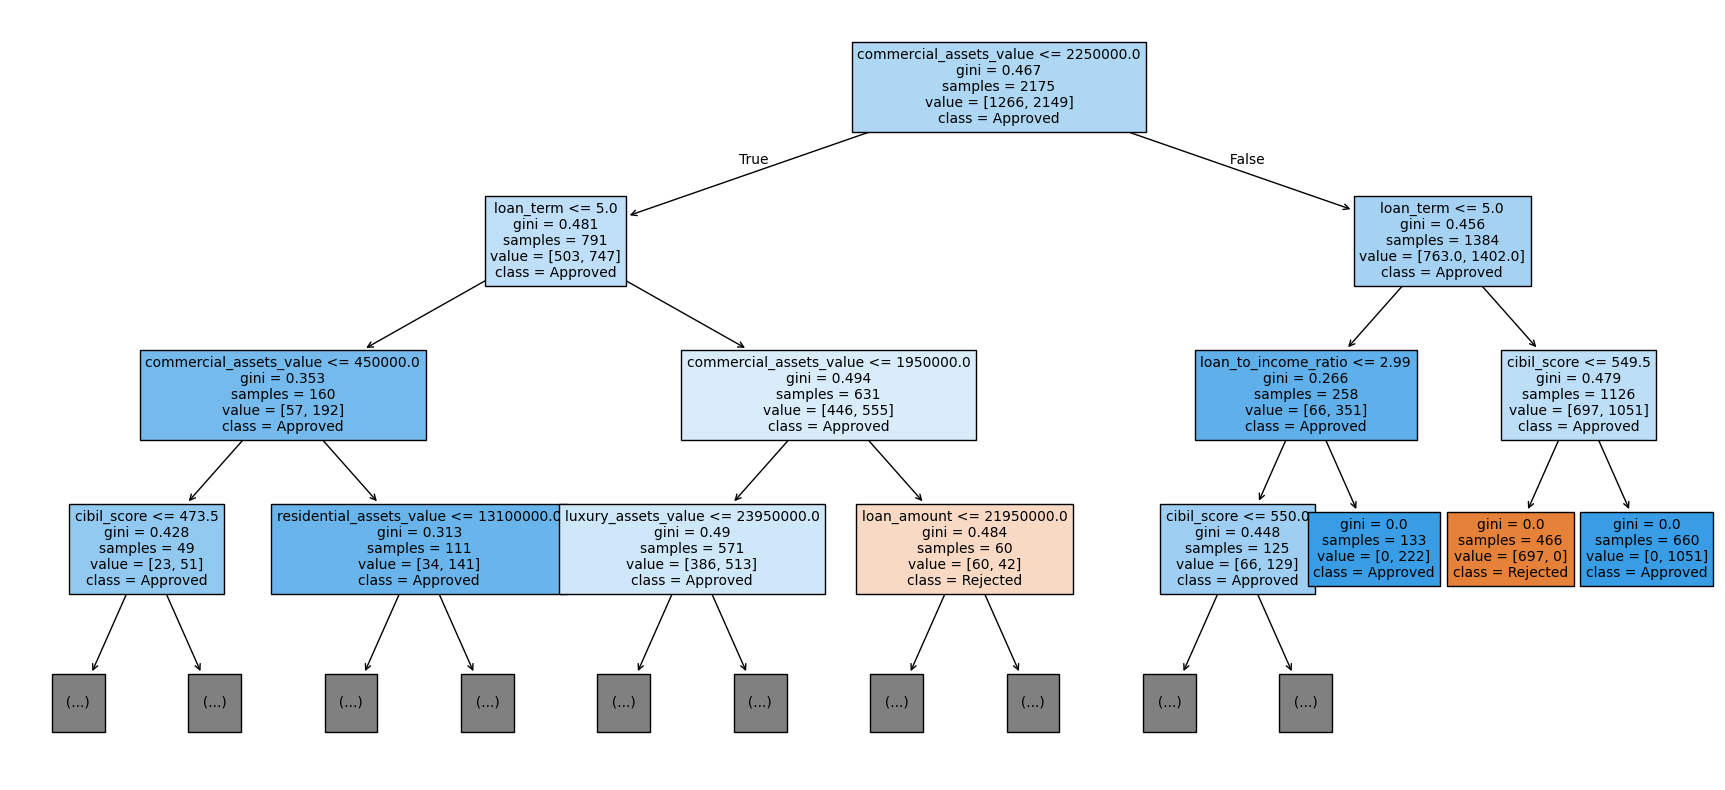

In [ ]:
single_tree = rf.estimators_[0]
plt.figure(figsize=(22,10))
plot_tree(single_tree,filled=True,feature_names=X.columns.tolist(),
          class_names=['Rejected','Approved'],
          fontsize = 10,max_depth = 3)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# ---------------------------
# LOAD DATA
# ---------------------------
df = pd.read_csv("C:\\Users\\saisu\\Downloads\\stock_details_5_years.csv")

# Convert date
df['Date'] = pd.to_datetime(df['Date'])

# Select one company
company = "AAPL"
data = df[df['Company'] == company].copy()

# Sort by date
data = data.sort_values('Date')

# ---------------------------
# FEATURE ENGINEERING
# ---------------------------

# Moving averages
data['MA5'] = data['Close'].rolling(5).mean()
data['MA10'] = data['Close'].rolling(10).mean()
data['MA20'] = data['Close'].rolling(20).mean()

# Exponential moving averages
data['EMA10'] = data['Close'].ewm(span=10).mean()
data['EMA20'] = data['Close'].ewm(span=20).mean()

# Daily return
data['Return'] = data['Close'].pct_change()

# Volatility
data['Volatility'] = data['Return'].rolling(10).std()

# Lag Features
for i in range(1, 11):
    data[f'Lag_{i}'] = data['Close'].shift(i)

# Target variable (next day price)
data['Target'] = data['Close'].shift(-1)

# Remove missing values
data.dropna(inplace=True)

# ---------------------------
# SELECT FEATURES
# ---------------------------

features = [
    'Open', 'High', 'Low', 'Volume',
    'MA5', 'MA10', 'MA20',
    'EMA10', 'EMA20',
    'Return', 'Volatility'
]

for i in range(1, 11):
    features.append(f'Lag_{i}')

X = data[features]
y = data['Target']

# ---------------------------
# TRAIN TEST SPLIT
# ---------------------------

split = int(len(data) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# ---------------------------
# MODEL
# ---------------------------

model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train)

# ---------------------------
# PREDICTIONS
# ---------------------------

predictions = model.predict(X_test)

# ---------------------------
# EVALUATION
# ---------------------------

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

# Accuracy approximation
mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100
accuracy = 100 - mape

print("MAPE:", round(mape, 2), "%")
print("Approx Accuracy:", round(accuracy, 2), "%")

# ---------------------------
# FUTURE PREDICTION
# ---------------------------

last_row = X.iloc[-1:]

future_price = model.predict(last_row)

print("\nPredicted Next Day Price:")
print(round(future_price[0], 2))

# ---------------------------
# PLOT
# ---------------------------

plt.figure(figsize=(12,6))
plt.plot(y_test.values, label='Actual')
plt.plot(predictions, label='Predicted')
plt.title(f'{company} Stock Price Prediction')
plt.xlabel('Days')
plt.ylabel('Price')
plt.legend()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\saisu\\Downloads\\stock_details_5_years.csv'